# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

## Phase 4 – Mitigation: a toy example

Phase 3 (`phase3_propagation`) found a gap in separation and sufficiency for the South, and no gap in independence.
Section 3.6 explains it: southern pairs sit closer to the cut, because many southern jobs require no skill that
separates the candidates, so any noise flips more southern decisions. Section 3.6.5 says what this means for a
mitigation of Adecco's system:

* there is nothing to train: the matcher is a formula with seven known weights (phase 1), so pre-processing and
  in-processing, which act on a training set and on a loss, have no place to act;
* post-processing the decisions for equalized odds ([Hardt et al. 2016](https://papers.neurips.cc/paper_files/paper/2016/file/6a9659feb1216f14f7384ba499518b38-Paper.pdf)) can only bring the North down to the South;
* C is not the truth: it holds what our extractors recovered, so there is no label to fit a mitigation on.

So the techniques cannot be applied to the real case. To show how they work we build a toy case: one job
opening, its candidates, and a matcher learned from past decisions, with a known truth. The matcher does not read
the region: it reads how far each candidate lives from the opening, as Adecco's formula does with `Distance_match`,
and the distance is a proxy of the region. Leaving the sensitive attribute out of the model is called fairness
through unawareness, and proxies like this one are why it fails; the toy shows how. We take one technique from each
level of the mitigation taxonomy:

* **4.1** A toy hiring case: the candidates, the truth and the past decisions.
* **4.2** The baseline: a matcher learned from the past decisions.
* **4.3** Pre-processing: reweighing.
* **4.4** In-processing: the Prejudice Remover.
* **4.5** Post-processing: equalized odds, on the decisions and on the score.
* **4.6** Comparison.

Every decision is measured with the metrics of phase 3, computed by fairlearn's `MetricFrame`: the selection rate $r$ per
region with the SPD and DI of the South, $\text{SPD} = r_{\text{South}} - r_{\text{North}}$ and
$\text{DI} = r_{\text{South}} / r_{\text{North}}$ (independence), and the false negative and false positive rates
against the truth with the South's gaps (separation). The reference group is the North. The toy is a demonstration: its numbers say nothing about Adecco's data.

In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

### 4.1 A toy hiring case

The toy is one job opening in the North, with many candidates: one row per candidate, as one list of the real case,
but with a hire or reject decision per candidate instead of a cut in the ranked list. Each candidate has:

* two scores, `skills` and `experience`, uniform in $[0, 1]$ and independent of the region; four candidates in ten
  are from the South;
* a `distance` from the opening, 0 next door and 1 far away. The opening is in the North, so northern candidates
  have a distance uniform in $[0, 0.6]$ and southern ones in $[0.4, 1]$: the distance tells the region, with some
  overlap;
* the truth, `hired_truth`: whether the two scores add up to more than 1, plus a little noise,

  $$\text{hired\_truth} = \bigl[\,\text{skills} + \text{experience} + \varepsilon > 1\,\bigr],
  \qquad \varepsilon \sim \mathcal{N}(0,\ 0.15^2).$$

  Without the noise, the two scores would predict the truth perfectly, the matcher would make no errors apart from the bias, and the mitigations would have nothing to trade off.
* the past decision, `hired_past`: what the recruiters decided in the past. They followed the truth, with one
  exception: they rejected 30% of the qualified southern candidates, drawn at random. This is the only bias of the
  toy, and the matcher will learn from these decisions.

We draw a training set, from which the matcher learns, and a test set of the same size, on which we evaluate every
decision. The table gives, per region, the candidates of the training set and the share hired by the truth
and by the past decisions.

In [ ]:
from hiring_cv_bias.fairness.metrics import for_display
from hiring_cv_bias.fairness.mitigation import toy_candidates

N = 20_000
train = toy_candidates(N, seed=0)
test = toy_candidates(N, seed=1)
display(
    for_display(
        train.group_by("Location")
        .agg(
            pl.len().alias("candidates"),
            pl.col("hired_truth").mean(),
            pl.col("hired_past").mean(),
        )
        .sort("Location")
    )
)

Location,candidates,hired_truth,hired_past
"""NORTH""",12158,49.3,49.3
"""SOUTH""",7842,49.7,34.6


### 4.2 The baseline: a matcher learned from the past decisions

The matcher is a logistic regression on `skills`, `experience` and `distance`,

$$P(\text{hired}) = \sigma\bigl(\beta_0 + \beta_1\,\text{skills} + \beta_2\,\text{experience} + \beta_3\,\text{distance}\bigr),
\qquad \sigma(z) = \frac{1}{1 + e^{-z}},$$

and a candidate is hired when $P(\text{hired}) > 0.5$. It is scikit-learn's `LogisticRegression` without
regularization, trained on the past decisions. The first table gives its coefficients. The second evaluates its
decisions on the test set against the truth, with the accuracy and the metrics listed at the start of this phase.

In [ ]:
from hiring_cv_bias.fairness.mitigation import (
    coefficients_table,
    decide,
    fit_matcher,
    mitigation_table,
)

models = {"baseline": fit_matcher(train)}
display(coefficients_table(models))
test = decide(test, models["baseline"], "baseline")
display(for_display(mitigation_table(test, ["baseline"]), ratios=["di"]))

term,baseline
"""intercept""",-6.32
"""skills""",6.56
"""experience""",6.64
"""distance""",-1.82


method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6


The matcher learned the bias without seeing the region. The coefficient of `distance` is negative: a candidate who
lives far from the opening needs higher scores to be hired, although the truth ignores the distance. It learned
this because the qualified candidates with a wrong label are all from the South, and southern candidates live far. Against the truth, the
South is hired 9 points less than the North and its DI is at the 0.8 of the four-fifths rule: independence fails.
Separation fails too: the matcher misses three qualified southern candidates in ten, twice the North's share, and
hires fewer unqualified southern ones. The model repeats the bias of its labels through a proxy. Phase 3 was
different: there independence held and only the error rates differed.

### 4.3 Pre-processing: reweighing

Reweighing ([Kamiran and Calders 2012](https://doi.org/10.1007/s10115-011-0463-8)) changes the training data, not the model. Every row gets the weight

$$w(a, y) = \frac{P(A = a)\,P(Y = y)}{P(A = a,\ Y = y)}$$

of its region $a$ and past label $y$. The weight compares how many candidates have that region and that label
with how many there would be if the region and the label were independent. A combination that occurs less often
than that, like the hired southern candidates, gets a weight above 1; one that occurs more often, like the rejected
southern candidates, gets a weight below 1. In the weighted data the region and the label are independent.
fairlib's `Reweighing` computes the weights; the table gives the four of them, with the number of candidates in
each cell. We then train the matcher again with them, as the sample weights of the regression.

In [ ]:
from hiring_cv_bias.fairness.mitigation import reweighing_weights, weights_table

weights = reweighing_weights(train)
display(for_display(weights_table(train, weights), ratios=["weight"]))
models["reweighing"] = fit_matcher(train, weights=weights)
test = decide(test, models["reweighing"], "reweighing")
display(for_display(mitigation_table(test, ["baseline", "reweighing"]), ratios=["di"]))

Location,hired_past,candidates,weight
"""NORTH""",true,5996,0.88
"""NORTH""",false,6162,1.11
"""SOUTH""",true,2711,1.26
"""SOUTH""",false,5131,0.86


method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""reweighing""",87.5,45.1,40.4,-4.7,0.9,16.4,24.0,7.6,6.6,3.7,-3.0


The hired southern candidates weigh 1.26 and the rejected ones 0.86; the North moves the other way, by less. The
retrained matcher halves the gap: the South's SPD goes from −9.4 to −4.7 points, its DI from 0.8 to 0.9, and the
gaps in the two error rates halve too. The accuracy against the truth goes up, since the weights pull the matcher
away from the biased labels. Part of the bias remains: the weights balance the label between the regions on
average, but the wrongly rejected candidates keep their wrong label, and the matcher still learns from them.

### 4.4 In-processing: the Prejudice Remover

The Prejudice Remover ([Kamishima et al. 2012](https://doi.org/10.1007/978-3-642-33486-3_4)) changes the loss of the model. It adds a fairness term, $\eta$
times the mutual information between the prediction and the region,

$$\mathcal{L}(\beta) = \text{cross-entropy}(\beta) + \eta\, I(\hat Y; A),
\qquad I(\hat Y; A) = \sum_{y \in \{0, 1\}} \sum_{a} P(y, a) \log \frac{P(y, a)}{P(y)\,P(a)},$$

where $P(\hat Y = 1 \mid A = a)$ is the mean of $P(\text{hired})$ over the candidates of region $a$. The term is 0
when the prediction is independent of the region, and grows with the dependence, in either direction. The
trade-off parameter $\eta$ sets the weight of this term against the cross-entropy. We use fairlib's `PrejudiceRemover`:
it trains the same logistic regression as 4.2 with Adam, in 20 passes over the training set, computing the term on
every batch; the region is passed to the loss, not to the model. We train with three values of $\eta$.

In [ ]:
from hiring_cv_bias.fairness.mitigation import fit_prejudice_remover

ETAS = (1, 5, 20)
for eta in ETAS:
    name = f"prejudice_remover_{eta}"
    models[name] = fit_prejudice_remover(train, eta=eta)
    test = decide(test, models[name], name)
display(
    for_display(
        mitigation_table(
            test, ["baseline", *[f"prejudice_remover_{eta}" for eta in ETAS]]
        ),
        ratios=["di"],
    )
)

method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""prejudice_remover_1""",87.3,47.0,39.7,-7.3,0.84,14.4,25.3,10.9,8.5,3.6,-4.9
"""prejudice_remover_5""",87.9,45.2,41.9,-3.3,0.93,16.3,21.6,5.4,6.6,4.3,-2.3
"""prejudice_remover_20""",87.5,42.8,42.6,-0.2,0.99,19.3,20.8,1.5,4.9,4.8,-0.1


The larger $\eta$, the smaller the gap: with $\eta = 20$ the two regions are hired at the same rate (SPD −0.2, DI 0.99)
and the two error gaps are within two points. The accuracy rises a little, because the labels are biased against
the South and the term moves the matcher away from that bias.
The gap closes from both sides: the South's false negative rate falls from 29.5% to 20.8%, the North's rises
from 15.2% to 19.3%. The South gets closer to the truth and the North moves away from it: its selection rate falls
from 46.5% to 42.8%, while the truth hires 49.3% of the North (4.1).

### 4.5 Post-processing: equalized odds

The post-processing of [Hardt et al. 2016](https://papers.neurips.cc/paper_files/paper/2016/file/6a9659feb1216f14f7384ba499518b38-Paper.pdf) keeps the baseline matcher and changes what it outputs, at random and
per region, so that the two regions get the same true positive rate and the same false positive rate with the
fewest expected errors. fairlearn's `ThresholdOptimizer` does it in two ways.

*On the decisions.* The only input is the hire or reject decision, as in section 3.6.5 with Adecco's: a hired
candidate stays hired with a probability `keep` and a rejected one becomes hired with a probability `add`, both per
region. After the flips, a region with true positive rate $\text{TPR}$ and false positive rate $\text{FPR}$ has

$$\text{TPR}' = \text{keep} \cdot \text{TPR} + \text{add} \cdot (1 - \text{TPR}),
\qquad \text{FPR}' = \text{keep} \cdot \text{FPR} + \text{add} \cdot (1 - \text{FPR}).$$

*On the score.* The input is $P(\text{hired})$ of the matcher, and the optimizer picks a threshold per region
instead of the common 0.5.

We fit both on the training set against the truth: the method needs true labels, which the toy has and the real case has not. The first table gives, per
region, the rates before and after the flips and the two probabilities, and the figure draws them as in section 3.6.5:
each region can reach only the rates inside its quadrilateral. The second table evaluates both decisions on the test set.

group,pairs,tpr,fpr,keep,add,tpr_after,fpr_after
"""NORTH""",12158,84.2,8.0,0.86,0.0,72.2,6.9
"""SOUTH""",7842,71.0,2.8,1.0,0.04,72.2,6.9


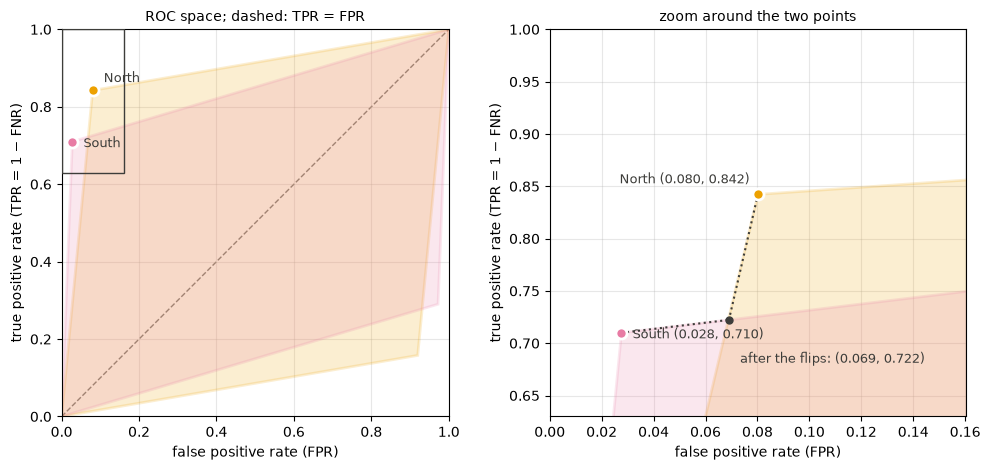

method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""equalized_odds""",82.5,39.9,40.0,0.1,1.0,27.4,28.1,0.7,7.2,7.1,-0.1
"""equalized_odds_score""",88.2,49.7,49.2,-0.5,0.99,11.7,13.8,2.1,11.1,11.0,-0.2


In [ ]:
from hiring_cv_bias.fairness.mitigation import (
    apply_equalized_odds,
    decision_input,
    equalized_odds_on_decisions,
    equalized_odds_on_score,
    features,
    flip_table,
)
from hiring_cv_bias.fairness.plots import plot_reachable_region

train = decide(train, models["baseline"], "baseline")
on_decisions = equalized_odds_on_decisions(train, "baseline")
flips = flip_table(on_decisions, train, "baseline")
display(for_display(flips, ratios=["keep", "add"]))
plot_reachable_region(flips)
plt.show()
test = apply_equalized_odds(
    test, on_decisions, decision_input(test, "baseline"), "equalized_odds"
)

on_score = equalized_odds_on_score(train, models["baseline"])
test = apply_equalized_odds(test, on_score, features(test), "equalized_odds_score")
display(
    for_display(
        mitigation_table(test, ["baseline", "equalized_odds", "equalized_odds_score"]),
        ratios=["di"],
    )
)

*On the decisions.* A flip adds no information: the optimizer cannot tell the qualified rejected candidates from the
others, so hiring some at random raises the true and false positive rates together. Both regions move, unlike in
section 3.6.5: the South's true positive rate goes from 71% to 72%, the North's falls from 84% to 72%. On the test set
the rates of the two regions match within one point, but the accuracy falls to 82.5%, the lowest of all the decisions.
This is the leveling down of section 3.6.5, in a milder form, and two identical candidates can now get different
outcomes.

*On the score.* The optimizer can now tell which rejected candidates are closest to being hired. It lowers the
threshold of both regions, the South's more, which corrects part of what the matcher learned from the biased labels. Both regions are hired at about 49%, the error rates are within two points, and the accuracy rises
to 88.2%, the highest of all the decisions.

So the post-processing levels down only when it has nothing but the decisions. In the real case that is the
situation: the selection is the top half of each list, a quota and not a threshold on a score, so a threshold per
region would change how many candidates each list selects.

### 4.6 Comparison

The table and the figure put the decisions together, with $\eta = 20$ for the Prejudice Remover, the best of the
three values of 4.4. The coefficients show what the two retrained matchers changed; the two post-processings keep
the baseline's.

term,baseline,reweighing,prejudice_remover_20
"""intercept""",-6.32,-6.95,-6.49
"""skills""",6.56,6.86,6.09
"""experience""",6.64,6.92,6.1
"""distance""",-1.82,-0.98,-0.18


method,accuracy,rate_NORTH,rate_SOUTH,spd,di,fnr_NORTH,fnr_SOUTH,fnr_diff,fpr_NORTH,fpr_SOUTH,fpr_diff
"""baseline""",86.5,46.5,37.1,-9.4,0.8,15.2,29.5,14.3,8.2,2.6,-5.6
"""reweighing""",87.5,45.1,40.4,-4.7,0.9,16.4,24.0,7.6,6.6,3.7,-3.0
"""prejudice_remover_20""",87.5,42.8,42.6,-0.2,0.99,19.3,20.8,1.5,4.9,4.8,-0.1
"""equalized_odds""",82.5,39.9,40.0,0.1,1.0,27.4,28.1,0.7,7.2,7.1,-0.1
"""equalized_odds_score""",88.2,49.7,49.2,-0.5,0.99,11.7,13.8,2.1,11.1,11.0,-0.2


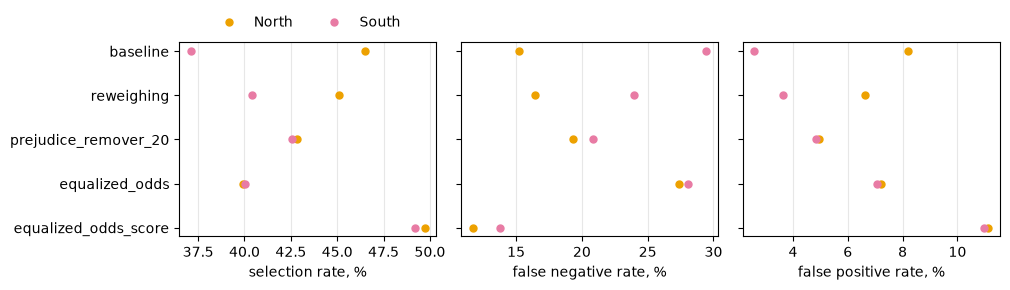

In [ ]:
from hiring_cv_bias.fairness.plots import plot_mitigation

METHODS = [
    "baseline",
    "reweighing",
    "prejudice_remover_20",
    "equalized_odds",
    "equalized_odds_score",
]
display(coefficients_table({m: models[m] for m in METHODS if m in models}))
comparison = mitigation_table(test, METHODS)
display(for_display(comparison, ratios=["di"]))
plot_mitigation(comparison)
plt.show()

The coefficient of `distance` goes from −1.82 to −0.98 with reweighing and to −0.18 with the Prejudice Remover, so
both retrained matchers rely less on the proxy.

In the figure, the two dots of every row are closer than in the baseline. The South's selection rate moves toward
the truth; the North's moves away from it in every row but the last.

The two retrained matchers gain accuracy: the bias is in the labels and the truth is the same in both regions, so a
matcher that follows the labels less follows the truth more.

The Prejudice Remover and the post-processing of the decisions reach the same gaps, within two points, but the first
mostly helps the South and the second mostly hurts the North:

* the Prejudice Remover retrains the matcher. The South's false negative rate falls from 29.5% to 20.8%, the North's rises from
  15.2% to 19.3%, and the accuracy rises by one point;
* the post-processing of the decisions keeps the matcher and flips its decisions. The South's false negative rate goes
  from 29.5% to 28.1%, the North's from 15.2% to 27.4%, and the accuracy falls by four points.

The post-processing of the score does better than both, with the same matcher: it lowers the false negative rate of
both regions, to 11.7% and 13.8%, by hiring more in both (49.7% and 49.2%), at the price of a higher false positive
rate (11% in both). The score tells it which candidates sit closest to the cut, and the flips have no such information.

### Findings for the toy

* **Leaving the region out of the model (fairness through unawareness) does not help.** The matcher never reads the
  region, but it learns the bias of the past decisions through the distance from the opening, a proxy that the truth
  ignores: SPD −9 points, DI 0.8, three qualified southern candidates in ten missed against one and a half in the
  North (4.2).
* **Pre-processing: reweighing halves the gap** and improves the accuracy against the truth, but part of the bias
  remains: the matcher still reads the proxy (4.3, 4.6).
* **In-processing: the Prejudice Remover closes the gap as far as $\eta$ asks**, with no loss of accuracy here, by moving both
  regions: the South toward the truth, the North away from it (4.4).
* **Post-processing: equalized odds brings the rates within about two points, and what it costs depends on what it
  reads.** On the decisions alone it has the largest loss of accuracy: with no new information it can only lower the
  North and give the South a point, both at random. On the score it has the highest accuracy of all: lower thresholds,
  the South's more, bring both regions closer to the truth (4.5, 4.6).
* **The real case lacks what these techniques need.** They need a matcher that is trained, so that weights or a loss
  term can act on it (4.3, 4.4); a score with a threshold, so that the threshold can move per region (4.5); and true
  labels, which the post-processing needs to fit its rates (4.5). In phase 3 the matcher is a fixed formula, the
  selection is a quota per list and C is not the truth. The only technique we could test on the real data, the
  post-processing of the decisions, would level the North down to the South, as section 3.6.5 shows on the real data
  and 4.5 on the toy.